In [54]:
import numpy as np 
import matplotlib.pyplot as plt

# Análise harmonica 

$f_i(\bar{p}) = \sum_{k=0}^{L}{p_k \sin(k x_i) + {} p_{k + L + 1} \cos(k x_i)}$

In [69]:
# Primeiro vamos criar alguns dados sintéticos 
N = 100
x = np.linspace(0, 10, N)
L = 3 # Ordem da minha análise harmônica
M = (L + 1) * 2 # N de parametros
true_p = np.zeros(M)
true_p[1] = 5
true_p[3] = 2
true_p[-1] = 3
y = np.zeros(N)

for k in range(L + 1):
    y += true_p[k] * np.sin(k * x) + true_p[k + L + 1] * np.cos(k * x)

random = np.random.default_rng(2)
y += random.normal(0, 0.1 * np.abs(y).max(), N)

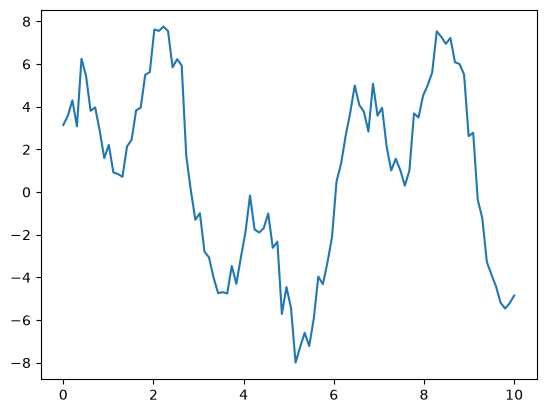

In [70]:
# Vamos plotar e ver a cara do nosso dado 

plt.plot(x, y)

In [71]:
# Vamos construir a nossa matriz jacobiana 
G = np.empty((N,M))

for k in range(L + 1):
    G[:, k] = np.sin(k * x)
    G[:, k + L + 1] = np.cos(k * x)

p = np.linalg.solve(G.T @ G, G.T @ y)

LinAlgError: Singular matrix

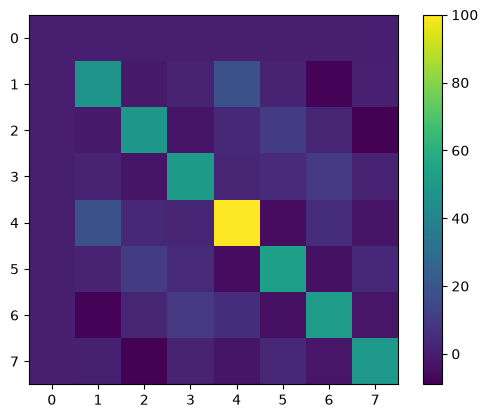

In [72]:
plt.imshow(G.T @ G)
plt.colorbar()

Notamos que a primeira linha e primeira coluna da nossa jacobiana = 0, isso acontece porque $\sin(0) = 0$ então torna nossa matriz singular (em que uma das linhas, ou colunas, é lineramente dependente de outra) 

Então podemos reescrever como: 

$f_i(\bar{p}) = p_0 + \sum_{k=1}^{L}{p_k \sin(k x_i) + {} p_{k + L} \cos(k x_i)}$

In [79]:
# Vamos refazer usando outra abordagem já que o termo p_0 não tem solução 
L = 6
M = 2 * L + 1
G = np.empty((N,M))
G[:,0] = 1 

for k in range(1, L + 1):
    G[:, k] = np.sin(k * x)
    G[:, k + L] = np.cos(k * x)

p = np.linalg.solve(G.T @ G, G.T @ y)

y_p = p[0] + sum(p[k] * np.sin(k * x) + p[k + L] * np.cos(k * x) for k in range(1, L + 1)) 

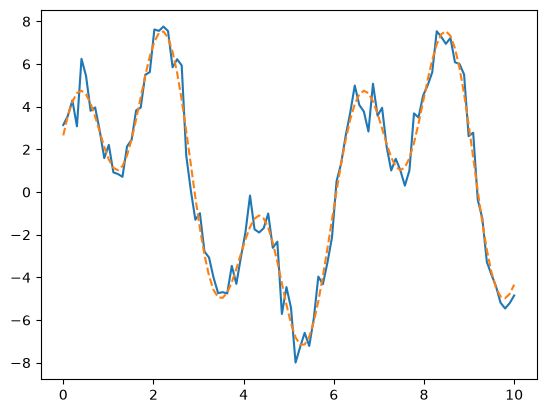

In [80]:
plt.plot(x,y)
plt.plot(x, y_p, '--')